# EO4FLOOD surface reflectance index

The surface reflectance index (SRI) is a satellite-observed proxy related to river discharge.
CNR-IRPI provides separate MODIS Terra, MODIS Aqua and Sentinel-2 time series, together with a
merged multi-mission series. This Ebro demonstration examines their sampling, index values,
uncertainty bounds and spatial distribution using the online Parquet asset in the STAC item.

The indices are dimensionless. They are neither discharge in m³/s nor raw spectral reflectance
restricted to values between zero and one. Different missions and the merged product can have
different distributions, so numerical differences alone do not establish an error.

| Column | Meaning |
|---|---|
| `site` | Sampling-site identifier |
| `time` | Timestamp on the daily delivery grid |
| `siteX`, `siteY` | Site longitude and latitude in geographic degrees |
| `surface_reflectance_index_MOD` | MODIS Terra index |
| `surface_reflectance_index_MYD` | MODIS Aqua index |
| `surface_reflectance_index_S2` | Sentinel-2 index |
| `*_uncertainty_min`, `*_uncertainty_max` | Delivered lower and upper bounds for each mission |
| `combined` | Merged multi-mission index |

A row on the daily grid does not imply an observation from every mission. Missing values remain missing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SRI_URL = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/surface_reflectance_index_series/Ebro_surface_reflectance_index.parquet'
SITE = 25
SERIES = {
    "MODIS Terra": "surface_reflectance_index_MOD",
    "MODIS Aqua": "surface_reflectance_index_MYD",
    "Sentinel-2": "surface_reflectance_index_S2",
    "Combined": "combined",
}
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})
sri = pd.read_parquet(SRI_URL).sort_values(["site", "time"])
sri.head()

,site,time,siteX,siteY,surface_reflectance_index_MOD,surface_reflectance_index_MYD,surface_reflectance_index_S2,surface_reflectance_index_MOD_uncertainty_max,surface_reflectance_index_MYD_uncertainty_max,surface_reflectance_index_S2_uncertainty_max,...,title,creation_time,institution,creator_institution_e-mail,references,temporal_interval,version,Conventions,DOI,Acknowledgements
0,0,2016-01-01,0.192165,42.289719,NaN,NaN,NaN,20.0,20.0,NaN,...,ESA EO4FLOOD project Surface Reflectance Index...,22-Sep-2026 09:18:51,National Research Council - Research Institut...,luca.ciabatta@cnr.it,"Tarpanelli et al., 2025. The Potential of EO D...",Jan-01-2016 to Dec-31-2024 23:00,Version 2.0,CF-1.11-draft,10.5281/zenodo.17787732,European Space Agency EO4FLOOD project Contrac...
1,0,2016-01-02,0.192165,42.289719,NaN,NaN,NaN,20.0,20.0,NaN,...,ESA EO4FLOOD project Surface Reflectance Index...,22-Sep-2026 09:18:51,National Research Council - Research Institut...,luca.ciabatta@cnr.it,"Tarpanelli et al., 2025. The Potential of EO D...",Jan-01-2016 to Dec-31-2024 23:00,Version 2.0,CF-1.11-draft,10.5281/zenodo.17787732,European Space Agency EO4FLOOD project Contrac...
2,0,2016-01-03,0.192165,42.289719,NaN,NaN,NaN,20.0,20.0,NaN,...,ESA EO4FLOOD project Surface Reflectance Index...,22-Sep-2026 09:18:51,National Research Council - Research Institut...,luca.ciabatta@cnr.it,"Tarpanelli et al., 2025. The Potential of EO D...",Jan-01-2016 to Dec-31-2024 23:00,Version 2.0,CF-1.11-draft,10.5281/zenodo.17787732,European Space Agency EO4FLOOD project Contrac...
3,0,2016-01-04,0.192165,42.289719,NaN,NaN,NaN,20.0,20.0,NaN,...,ESA EO4FLOOD project Surface Reflectance Index...,22-Sep-2026 09:18:51,National Research Council - Research Institut...,luca.ciabatta@cnr.it,"Tarpanelli et al., 2025. The Potential of EO D...",Jan-01-2016 to Dec-31-2024 23:00,Version 2.0,CF-1.11-draft,10.5281/zenodo.17787732,European Space Agency EO4FLOOD project Contrac...
4,0,2016-01-05,0.192165,42.289719,NaN,NaN,NaN,20.0,20.0,NaN,...,ESA EO4FLOOD project Surface Reflectance Index...,22-Sep-2026 09:18:51,National Research Council - Research Institut...,luca.ciabatta@cnr.it,"Tarpanelli et al., 2025. The Potential of EO D...",Jan-01-2016 to Dec-31-2024 23:00,Version 2.0,CF-1.11-draft,10.5281/zenodo.17787732,European Space Agency EO4FLOOD project Contrac...


## Sites and spatial context

The basin-wide file contains several sampling sites. The map locates them and colours each by
the median available combined index. This is a summary of each site's observed record; it is not
a map of river discharge or an area-weighted basin mean.

,longitude,latitude,combined_observations,median_combined_index
site,,,,
0,0.192165,42.289719,366,1.052628
1,0.721319,41.681782,1973,1.305554
2,-0.772221,41.902447,1993,2.123500
3,-3.043391,42.785522,1201,0.873012
4,-0.552953,42.580353,1665,0.939685
5,-2.875945,42.580868,1252,0.858798
6,0.196609,41.622246,1984,1.258257
7,-0.841700,41.668781,1955,0.798643
8,-0.116373,42.501152,1546,1.075456


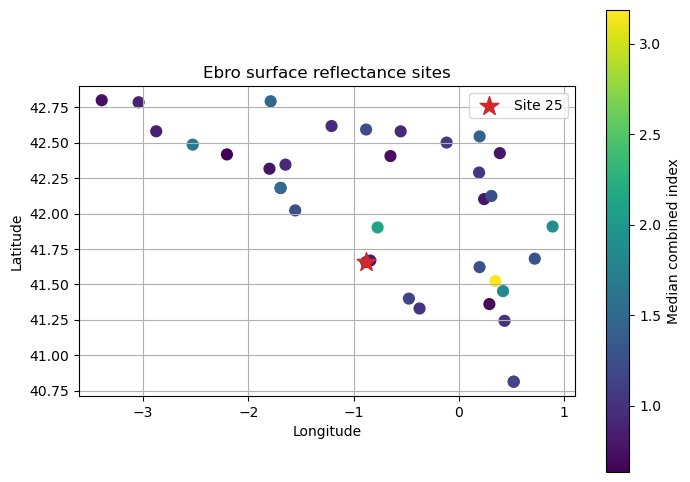

In [2]:
sites = sri.groupby("site").agg(
    longitude=("siteX", "first"), latitude=("siteY", "first"),
    combined_observations=("combined", "count"), median_combined_index=("combined", "median")
)
display(sites)
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(sites.longitude, sites.latitude, c=sites.median_combined_index, cmap="viridis", s=60)
fig.colorbar(points, ax=ax, label="Median combined index")
ax.scatter(sites.loc[SITE, "longitude"], sites.loc[SITE, "latitude"],
           marker="*", color="tab:red", s=200, label=f"Site {SITE}")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Ebro surface reflectance sites")
ax.set_aspect(1 / np.cos(np.deg2rad(sites.latitude.mean())))
ax.legend()
plt.show()

## Mission series and uncertainty bounds

Separate panels retain the sampling and scale of each mission at site 25. The shaded envelopes
are the delivered lower and upper uncertainty bounds, which need not be symmetric. Some delivered bounds do not enclose the corresponding index value; they are displayed as supplied.
The combined series is displayed separately because no corresponding uncertainty columns are supplied for it.

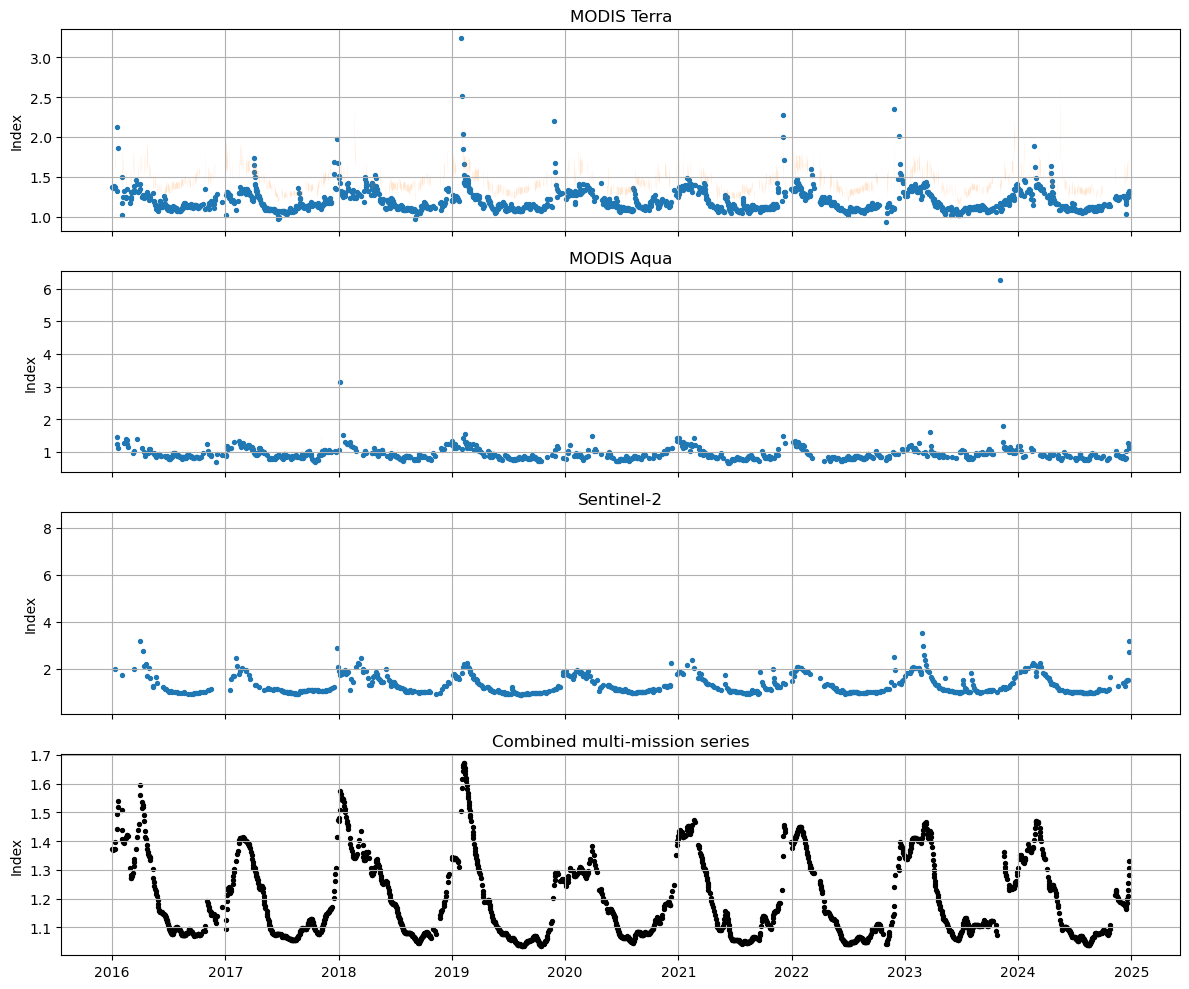

In [3]:
site = sri.loc[sri.site == SITE].set_index("time")
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(12, 10))
for (label, variable), ax in zip(list(SERIES.items())[:3], axes[:3]):
    ax.scatter(site.index, site[variable], s=8, label=label)
    lower = site[f"{variable}_uncertainty_min"].where(site[variable].notna())
    upper = site[f"{variable}_uncertainty_max"].where(site[variable].notna())
    ax.fill_between(site.index, lower, upper, alpha=0.2)
    ax.set(ylabel="Index", title=label)
axes[3].scatter(site.index, site.combined, s=8, color="black")
axes[3].set(ylabel="Index", title="Combined multi-mission series")
fig.tight_layout()
plt.show()

## Monthly behaviour and observation coverage

Monthly means summarise available values without filling gaps. The coverage panel reports the
fraction of daily grid rows with a value in each month. Large differences in availability can
make two monthly means represent different observation dates, even at the same site.

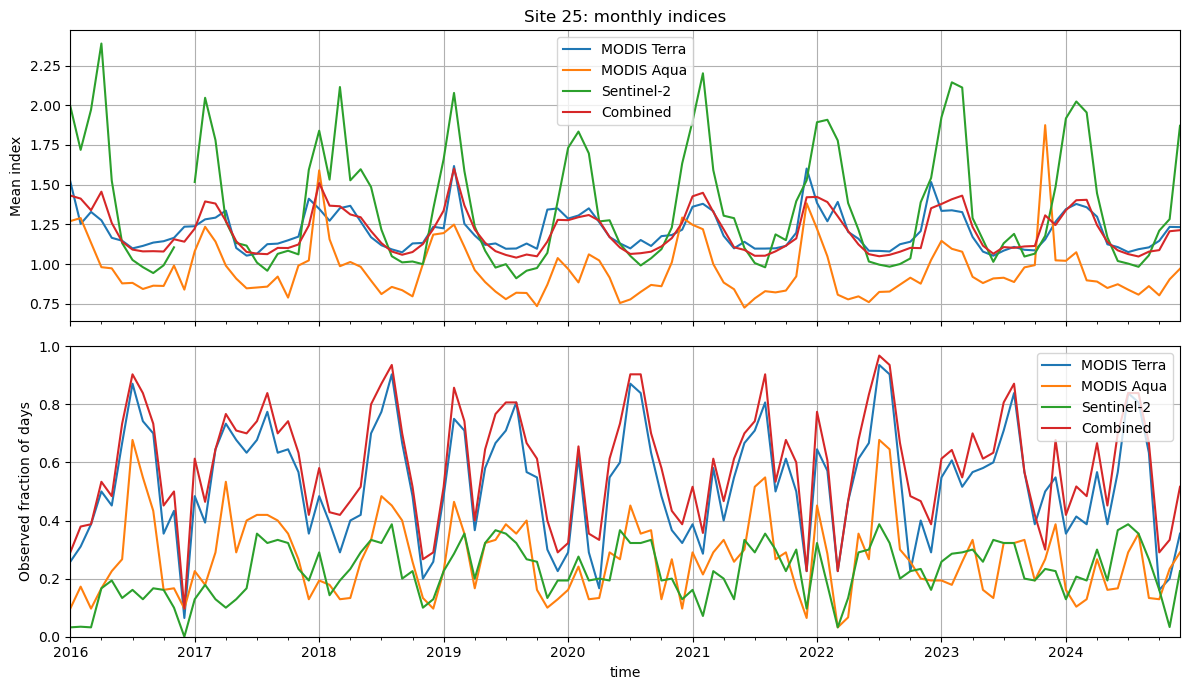

,MODIS Terra,MODIS Aqua,Sentinel-2,Combined
count,1738.000000,888.000000,746.000000,1952.000000
mean,1.185900,0.935038,1.304478,1.182235
std,0.145753,0.248495,0.400064,0.137744
min,0.938510,0.656361,0.898540,1.034930
25%,1.095976,0.818323,1.016582,1.074554
50%,1.136635,0.881582,1.118361,1.119591
75%,1.249073,1.001839,1.530698,1.283801
max,3.237074,6.267574,3.509489,1.671007


In [4]:
series = site[list(SERIES.values())].rename(columns={v: k for k, v in SERIES.items()})
monthly = series.resample("MS").mean()
coverage = series.notna().resample("MS").mean()
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7))
monthly.plot(ax=axes[0], ylabel="Mean index", title=f"Site {SITE}: monthly indices")
coverage.plot(ax=axes[1], ylabel="Observed fraction of days", ylim=(0, 1))
fig.tight_layout()
plt.show()
display(series.describe())

## Seasonal pattern and agreement

The seasonal curves average the available monthly means for each calendar month. Correlations
use only overlapping non-missing dates for each pair, with at least 20 paired observations.
The combined series is derived from satellite inputs, so its correlation with an input is not
an independent validation. Pair counts provide the sampling context for each correlation.

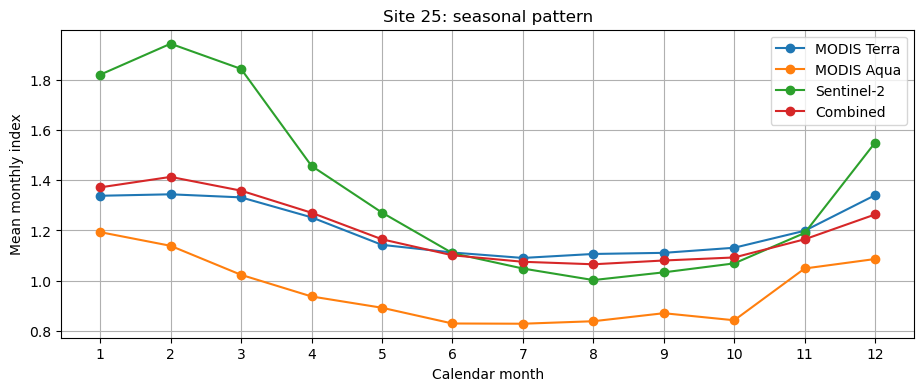

,MODIS Terra,MODIS Aqua,Sentinel-2,Combined
Paired observation counts,,,,
MODIS Terra,1738,789,601,1731
MODIS Aqua,789,888,291,885
Sentinel-2,601,291,746,743
Combined,1731,885,743,1952


,MODIS Terra,MODIS Aqua,Sentinel-2,Combined
Paired-date correlation,,,,
MODIS Terra,1.000000,0.398492,0.654944,0.725045
MODIS Aqua,0.398492,1.000000,0.615808,0.758135
Sentinel-2,0.654944,0.615808,1.000000,0.863539
Combined,0.725045,0.758135,0.863539,1.000000


In [5]:
monthly.groupby(monthly.index.month).mean().plot(
    marker="o", xlabel="Calendar month", ylabel="Mean monthly index", xticks=range(1, 13),
    title=f"Site {SITE}: seasonal pattern")
plt.show()
valid = series.notna().astype(int)
display(valid.T.dot(valid).rename_axis("Paired observation counts"))
display(series.corr(min_periods=20).rename_axis("Paired-date correlation"))